In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print(f"All Succeffully imported")

All Succeffully imported


In [5]:
df =  pd.read_csv("loan.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10614 entries, 0 to 10613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            10614 non-null  object 
 1   Gender             10179 non-null  object 
 2   Married            10504 non-null  object 
 3   Dependents         10614 non-null  float64
 4   Education          10614 non-null  object 
 5   Self_Employed      9569 non-null   object 
 6   ApplicantIncome    10614 non-null  int64  
 7   CoapplicantIncome  10614 non-null  float64
 8   LoanAmount         9871 non-null   float64
 9   Loan_Amount_Term   10141 non-null  float64
 10  Credit_History     9074 non-null   float64
 11  Property_Area      10614 non-null  object 
 12  Loan_Status        10614 non-null  object 
dtypes: float64(5), int64(1), object(7)
memory usage: 1.1+ MB


In [10]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,10614.000000,10614.000000,9871.000000,10141.000000,9074.000000
mean,5369.806670,1595.608578,146.293182,340.666995,0.838439
std,5838.223071,2698.542671,85.311086,65.878868,0.368067
min,143.000000,0.000000,9.000000,12.000000,0.000000
25%,2859.250000,0.000000,100.000000,360.000000,1.000000
50%,3811.000000,1141.580000,127.000000,360.000000,1.000000
75%,5768.750000,2289.045000,168.000000,360.000000,1.000000
max,84630.000000,43197.900000,722.000000,480.000000,1.000000


In [43]:
print("Dataset Shape:", df.shape)
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Loan IDs:", df["Loan_ID"].duplicated().sum())
print("Unique Loan Status:", df["Loan_Status"].unique())

Dataset Shape: (10614, 13)
Duplicate Rows: 0
Duplicate Loan IDs: 0
Unique Loan Status: ['Y' 'N']


In [13]:
df["Dependents"] = df["Dependents"].replace("3+", 4).astype(float)

In [15]:
df["Dependents"] = df["Dependents"].fillna(0)

In [40]:
missing = df.isnull().sum()
missing[missing>0]

Gender               435
Married              110
Self_Employed       1045
LoanAmount           743
Loan_Amount_Term     473
dtype: int64

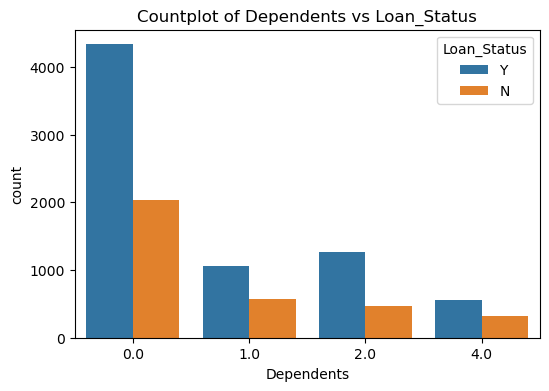

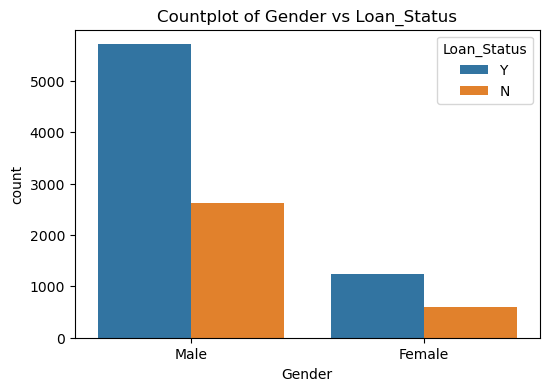

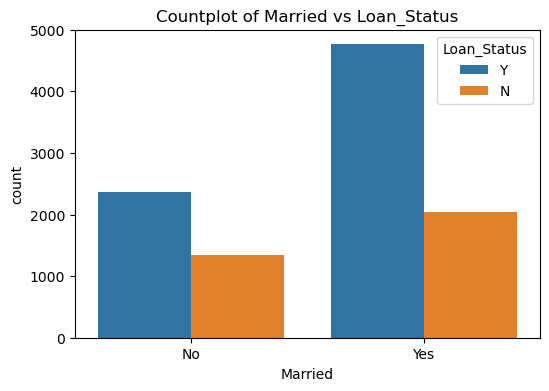

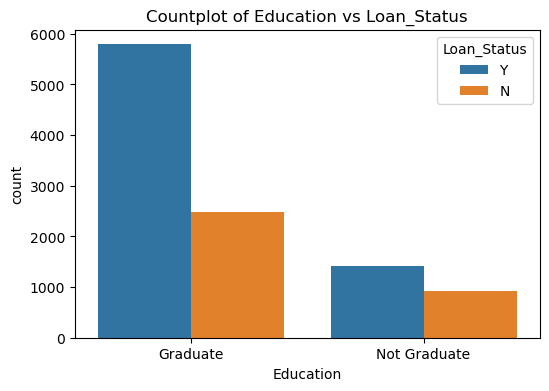

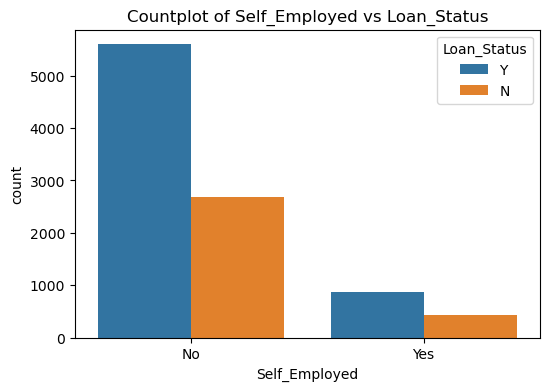

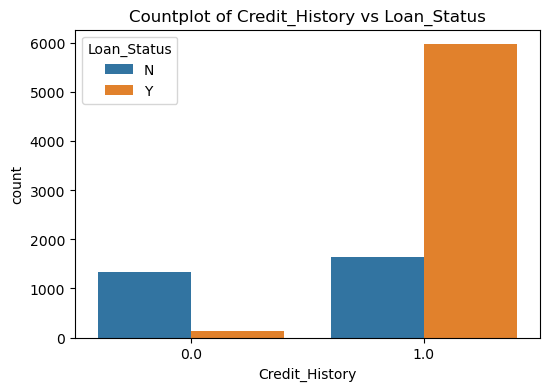

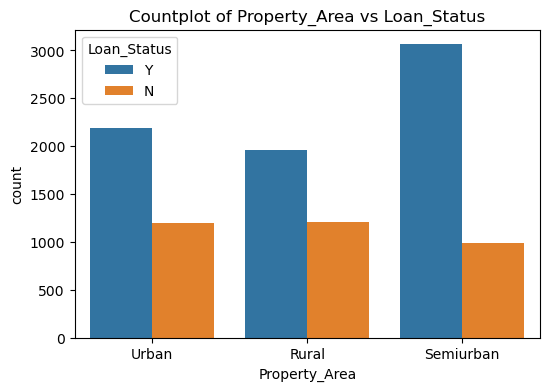

In [31]:
# countplot for target variable

columns = ["Dependents","Gender", "Married", "Education", "Self_Employed", "Credit_History", "Property_Area"]

for col in columns:
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, hue="Loan_Status", data=df)
    plt.title(f"Countplot of {col} vs Loan_Status")
    plt.show()

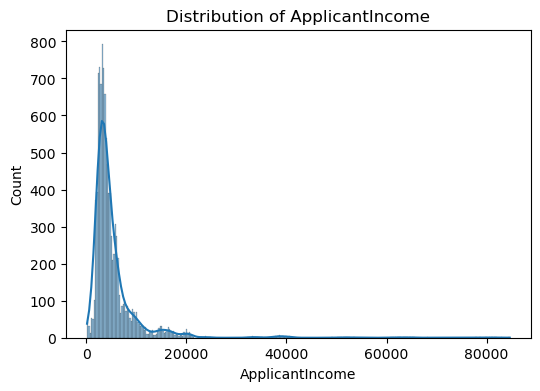

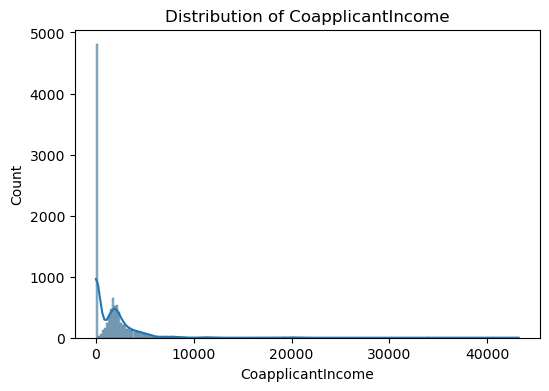

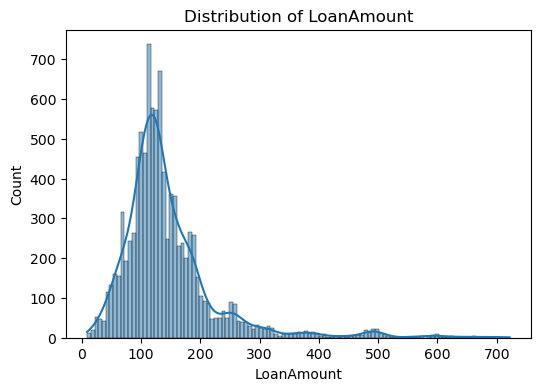

In [32]:
numerical_columns = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]

for col in numerical_columns:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

In [53]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

Self_Employed    1045
LoanAmount        743
Gender            435
Married           110
dtype: int64

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numerical_columns = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]
categorical_columns = ["Dependents","Gender", "Married", "Education", "Self_Employed", "Credit_History", "Property_Area"]

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer', SimpleImputer()),
                                                 ('scaler', StandardScaler())]),
                                 ['ApplicantIncome', 'CoapplicantIncome',
                                  'LoanAmount', 'Loan_Amount_Term']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Dependents', 'Gender', 'Married',
                                  'Education', 'Self_Employed',
                                  'Credit_History', 'Property_Area'])])

In [55]:
df = df.drop("Loan_ID", axis=1)
x = df.drop("Loan_Status", axis=1)
y = df["Loan_Status"].map({"Y": 1, "N": 0  })

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42,stratify=y)

(8491, 11)

In [59]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB


model_dict = {
    "Logistic Regression": LogisticRegression(),
    "Random Forest": RandomForestClassifier(),
    "SVM": SVC(),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(),
    "Naive Bayes": GaussianNB()
}

for name, model in model_dict.items():
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", model)])
    pipeline.fit(x_train, y_train)
    y_pred = pipeline.predict(x_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {accuracy*100:.2f}%")
    

Logistic Regression Accuracy: 72.96%
Random Forest Accuracy: 98.73%
SVM Accuracy: 84.60%
K-Nearest Neighbors Accuracy: 97.83%
Decision Tree Accuracy: 96.80%
Naive Bayes Accuracy: 71.27%


In [63]:
# hyperparameter tuning for Random Forest Classifier

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

best_params = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 10, 20, 30],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

best_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

random_search = RandomizedSearchCV(
    estimator=best_pipeline,
    param_distributions=best_params,
    n_iter=10,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(x_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV Score:", random_search.best_score_)


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 30}
Best CV Score: 0.977977414830729


In [64]:
best_model = random_search.best_estimator_

best_model.fit(x_train, y_train)

y_pred = best_model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Classifier Accuracy after Hyperparameter Tuning: {accuracy*100:.2f}%")

Random Forest Classifier Accuracy after Hyperparameter Tuning: 98.73%


In [65]:
# Save the complete pipeline
import joblib


joblib.dump(best_model, "loan_status_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [66]:
df.columns

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')